# XGBoost Model Training & Model Evaluation

In [2]:
import sys
import numpy as np
import xgboost as xgb
from pathlib import Path

# Setup the project root directory paths safely
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import standardized pipeline and evaluation modules
from src.pipeline import get_data
from src.evaluation import evaluate_predictions

print("Fetching pipeline data splits...")
data = get_data()

# Pull the compressed sparse matrices that XGBoost prefers for speed
X_train = data["X_train_sparse"]
y_train = data["y_train"]

X_val = data["X_val_sparse"]
y_val = data["y_val"]

X_test = data["X_test_sparse"]
y_test = data["y_test"]

# Initialize the Optimized XGBoost Classifier
# We set 'scale_pos_weight' using the calculation from your pipeline to handle the 1.1% fraud imbalance
model = xgb.XGBClassifier(
    n_estimators=1000,             # Maximum number of trees
    learning_rate=0.05,            # Stable, reliable step rate 
    max_depth=6,                   # Restricts tree depth to prevent noise overfitting
    scale_pos_weight=data["scale_pos_weight"], # CRUCIAL: Heavily penalizes fraud classification errors
    objective='binary:logistic',   # Outputs clean probabilities between 0 and 1
    eval_metric='aucpr',           # Focuses training directly on optimizing Precision-Recall AUC
    random_state=42,
    n_jobs=-1,                     # Uses all available processor cores for high-speed execution
    early_stopping_rounds=50       # Stops training if validation performance stalls for 50 trees
)

# Train the Model using the Validation Set to prevent overfitting
print("Training XGBoost model...")
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100                    # Prints progress updates every 100 trees
)

# Predict fraud probability scores on the Test Set
print("Generating test predictions...")
test_probabilities = model.predict_proba(X_test)[:, 1]

Fetching pipeline data splits...
Training XGBoost model...
[0]	validation_0-aucpr:0.08049
[100]	validation_0-aucpr:0.17192
[200]	validation_0-aucpr:0.17761
[229]	validation_0-aucpr:0.17834
Generating test predictions...


Running complete evaluation report...
 EVALUATION REPORT: XGBOOST
Accuracy:                 97.9499%
Fraud precision:          25.5985%
Fraud recall:             24.1487%
Fraud F1:                 24.8525%
PR-AUC (AP):              18.0940%
ROC-AUC:                  88.5281%
Recall @ FPR <= 1.00%:    24.1487%
FPR at chosen threshold:  0.9993%
Chosen Decision Boundary: 0.8922
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.26      0.24      0.25      2878

    accuracy                           0.98    205011
   macro avg       0.62      0.62      0.62    205011
weighted avg       0.98      0.98      0.98    205011



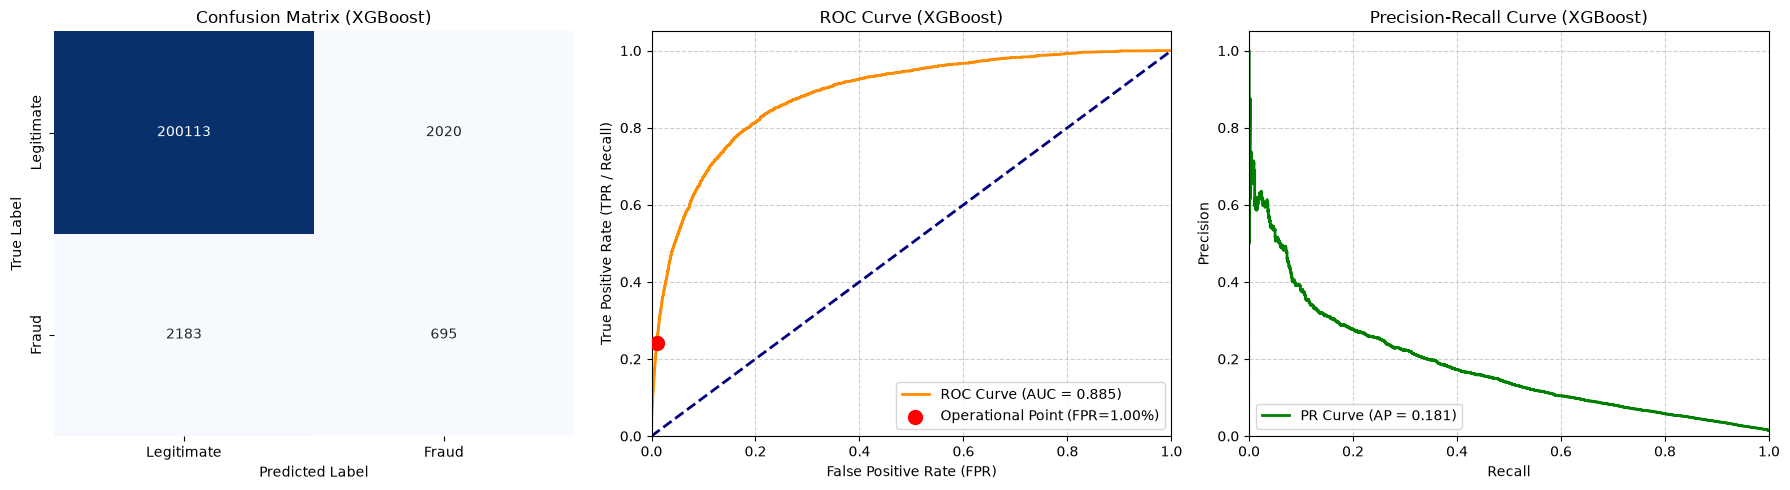

In [3]:
# Evaluate using your standardized evaluation script
print("Running complete evaluation report...")
evaluate_predictions(
    y_true=y_test,
    y_probs=test_probabilities,
    model_name="XGBoost"
)

In [ ]:
import os

# Create the models directory if it doesn't exist
MODELS_DIR = Path(PROJECT_ROOT) / "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Save the XGBoost model structure using its native JSON format
xgb_save_path = MODELS_DIR / "xgboost_model.json"
model.save_model(str(xgb_save_path))

print(f"XGBoost model successfully saved to: {xgb_save_path}")

XGBoost model successfully saved to: C:\Users\shubh\projects\FairFraud\models\xgboost_model.json
